# XGBoost Classification: Heart Disease

This notebook demonstrates a complete **binary classification** workflow with XGBoost. It uses the repository's UCI heart-disease dataset and predicts whether a patient has heart disease (`num > 0`) or not (`num = 0`). This is an educational example, not a medical diagnostic tool.

**Workflow:** understand the data -> define the target -> split into train/test sets -> preprocess missing and categorical values -> train XGBoost -> evaluate on unseen data -> inspect feature importance -> make a sample prediction.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import xgboost as xgb
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42
print(f"XGBoost version: {xgb.__version__}")

XGBoost version: 3.2.0


## 1. Load and understand the data

The original `num` field ranges from 0 to 4. For this binary task, 0 means no detected heart disease and any value above 0 means disease is present. We exclude `id` and `dataset` because they identify a row or data source rather than describing the patient.

In [2]:
data_path_candidates = [
    Path("classification") / "heart_disease_uci.csv",
    Path("..") / "classification" / "heart_disease_uci.csv",
]
data_path = next((path for path in data_path_candidates if path.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        "Could not find classification/heart_disease_uci.csv. Run this notebook "
        "from the repository root or the 'xg boost' folder."
    )

data = pd.read_csv(data_path)
if "num" not in data.columns:
    raise ValueError("Expected the target column 'num' in the heart-disease dataset.")

# Rows without a target cannot be used for supervised training.
data = data.dropna(subset=["num"]).copy()
data["target"] = (data["num"] > 0).astype(int)
excluded_columns = {"id", "dataset", "num", "target"}
feature_columns = [column for column in data.columns if column not in excluded_columns]
if not feature_columns:
    raise ValueError("No usable feature columns were found.")

X = data[feature_columns]
y = data["target"]
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

print(f"Loaded {len(data)} rows from {data_path}")
print(f"Features: {len(feature_columns)} ({len(numeric_features)} numeric, {len(categorical_features)} categorical)")
print("Target counts (0 = no disease, 1 = disease):")
display(y.value_counts().sort_index().rename(index={0: "No disease", 1: "Disease"}).to_frame("count"))
print("Missing values per feature (largest counts first):")
display(X.isna().sum().sort_values(ascending=False).head(15).to_frame("missing values"))
display(data.head())

Loaded 920 rows from ..\classification\heart_disease_uci.csv
Features: 13 (6 numeric, 7 categorical)
Target counts (0 = no disease, 1 = disease):


,count
target,
No disease,411
Disease,509


Missing values per feature (largest counts first):


,missing values
ca,611
thal,486
slope,309
fbs,90
oldpeak,62
trestbps,59
thalch,55
exang,55
chol,30
restecg,2


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,target
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2,1
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0,0


## 2. Create a stratified train/test split

The test set is held back until final evaluation. Stratification preserves the approximate disease/no-disease ratio in both sets. Preprocessing is fitted inside the training pipeline, which prevents information from the test set leaking into training.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training rows: {len(X_train)}")
print(f"Test rows: {len(X_test)}")
print("Training class proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename(index={0: "No disease", 1: "Disease"}).to_frame("proportion"))

Training rows: 736
Test rows: 184
Training class proportions:


,proportion
target,
No disease,0.447011
Disease,0.552989


## 3. Preprocess and train XGBoost

XGBoost requires numeric inputs. The preprocessing pipeline fills numeric missing values with the training median, fills categorical missing values with the most frequent training value, and one-hot encodes categories. The pipeline applies the same transformations at prediction time.

In [5]:
numeric_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
])
categorical_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessing, numeric_features),
        ("categorical", categorical_preprocessing, categorical_features),
    ],
)

model = xgb.XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    reg_lambda=1.0,
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
classifier = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", model),
])

classifier.fit(X_train, y_train)
print("Training complete.")
classifier

Training complete.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tra

## 4. Evaluate on the held-out test set

Accuracy is the share of correct predictions. Precision measures how many predicted disease cases are correct; recall measures how many actual disease cases are detected; F1 balances precision and recall. ROC-AUC measures ranking quality across classification thresholds. For health-related tasks, review recall and precision alongside accuracy, especially when classes are imbalanced.

,test score
Accuracy,0.853
Precision,0.850
Recall,0.892
F1 score,0.871
ROC-AUC,0.909


Classification report (0 = no disease, 1 = disease):
              precision    recall  f1-score   support

  No disease       0.86      0.80      0.83        82
     Disease       0.85      0.89      0.87       102

    accuracy                           0.85       184
   macro avg       0.85      0.85      0.85       184
weighted avg       0.85      0.85      0.85       184



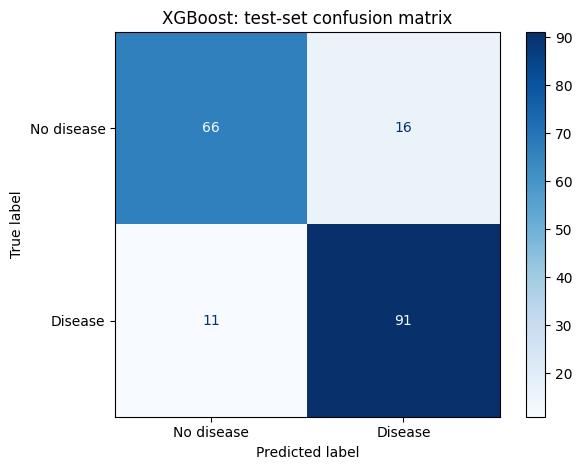

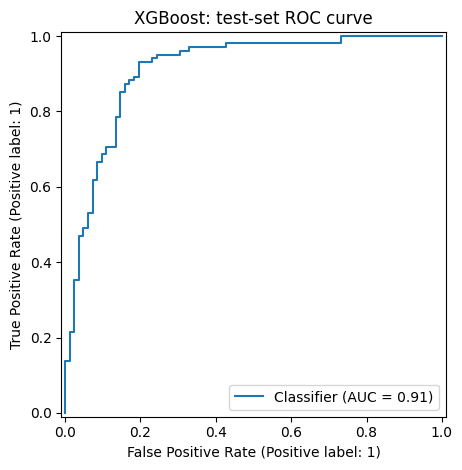

In [6]:
y_pred = classifier.predict(X_test)
y_probability = classifier.predict_proba(X_test)[:, 1]

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_probability),
}
display(pd.DataFrame.from_dict(metrics, orient="index", columns=["test score"]).round(3))

print("Classification report (0 = no disease, 1 = disease):")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No disease", "Disease"],
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No disease", "Disease"],
    cmap="Blues",
)
plt.title("XGBoost: test-set confusion matrix")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, y_probability)
plt.title("XGBoost: test-set ROC curve")
plt.tight_layout()
plt.show()

## 5. Inspect feature importance and make a prediction

XGBoost's built-in importance is based on how the fitted trees use each transformed feature; it is useful for exploration but does not establish cause and effect. The final example predicts one held-out patient and reports the estimated probability for the disease class.

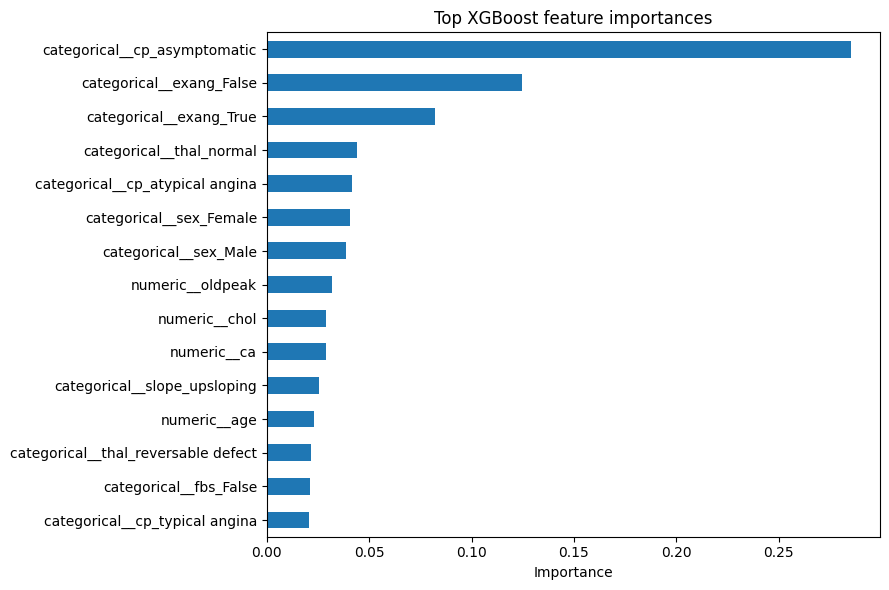

Predicted class: 0 (0 = no disease, 1 = disease)
Estimated disease probability: 43.4%
Actual class: 1


In [7]:
preprocessor_fitted = classifier.named_steps["preprocessor"]
model_fitted = classifier.named_steps["model"]
transformed_feature_names = preprocessor_fitted.get_feature_names_out()
feature_importance = (
    pd.Series(model_fitted.feature_importances_, index=transformed_feature_names)
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)
feature_importance.plot(kind="barh", figsize=(9, 6), title="Top XGBoost feature importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

sample_patient = X_test.iloc[[0]]
predicted_class = int(classifier.predict(sample_patient)[0])
disease_probability = float(classifier.predict_proba(sample_patient)[0, 1])
print(f"Predicted class: {predicted_class} (0 = no disease, 1 = disease)")
print(f"Estimated disease probability: {disease_probability:.1%}")
print(f"Actual class: {int(y_test.iloc[0])}")

## Cycle recap

1. Load and inspect labeled data.
2. Convert the original target into a binary label and remove identifier/source columns.
3. Split into training and test sets with stratification.
4. Learn missing-value handling and categorical encoding from training data.
5. Fit an `XGBClassifier` to learn nonlinear decision rules and feature interactions.
6. Evaluate once on the held-out test set using multiple metrics and plots.
7. Inspect model feature importance and use the fitted pipeline for new rows.

For a real application, use an appropriate validation strategy, tune the decision threshold for the intended use, assess calibration and subgroup performance, and obtain clinical review. This notebook is for learning only.